# Cirrhosis Outcomes Prediction — Baseline
**AOAI Task 4** · Multi-class classification · Tabular

Each row is a patient with liver cirrhosis, described by clinical measurements
(bilirubin, albumin, copper, prothrombin time, ...). Predict the patient's outcome at the end of the study.

| Class | Meaning |
|---|---|
| `C`  | Censored — alive at the end of the study |
| `CL` | Censored due to a liver transplant |
| `D`  | Deceased |

| | |
|---|---|
| **Target** | `Status` |
| **Metric** | **Multi-class log loss** (lower is better) |
| **Submission** | `id,Status_C,Status_CL,Status_D` — one probability per class, per test id |

### Notebook structure
1. Setup
2. Load data
3. EDA
4. Preprocessing & feature engineering
5. LightGBM with stratified K-fold cross-validation
6. Out-of-fold analysis
7. Generate submission
8. Ideas to improve

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import log_loss, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings('ignore')

SEED    = 42
TARGET  = 'Status'
CLASSES = ['C', 'CL', 'D']
np.random.seed(SEED)

# Works on Kaggle and locally (put the competition files in ./data)
COMPETITION = 'cirrhosis-outcomes-prediction-task'
CANDIDATES  = [Path(f'/kaggle/input/competitions/{COMPETITION}'), Path(f'/kaggle/input/{COMPETITION}'), Path('data')]
DATA_DIR    = next(p for p in CANDIDATES if p.exists())
print('Data directory:', DATA_DIR)

Data directory: data


## 2. Load Data

In [2]:
train = pd.read_csv(DATA_DIR / 'train.csv')
test  = pd.read_csv(DATA_DIR / 'test.csv')

print(f'Train: {train.shape} | Test: {test.shape}')
train.head()

Train: (15000, 20) | Test: (10000, 19)


,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
0,0,976.0,NaN,19358.0,F,NaN,NaN,NaN,N,0.6,NaN,3.63,NaN,NaN,NaN,NaN,350.0,10.3,3.0,C
1,1,4453.0,Placebo,15198.0,F,N,Y,N,N,0.6,NaN,3.15,23.0,1218.0,100.75,NaN,314.0,11.5,4.0,C
2,2,2698.0,NaN,23376.0,M,NaN,NaN,NaN,S,0.9,NaN,3.49,NaN,NaN,NaN,NaN,331.0,10.0,4.0,D
3,3,1542.0,D-penicillamine,18393.0,F,N,Y,Y,N,1.1,288.0,3.12,262.0,1062.0,75.95,114.0,228.0,11.0,4.0,C
4,4,2255.0,D-penicillamine,22646.0,F,N,N,N,N,0.5,NaN,3.89,13.0,663.0,66.65,NaN,146.0,10.6,1.0,C


## 3. EDA

Status
C     0.670
D     0.304
CL    0.027
Name: proportion, dtype: float64


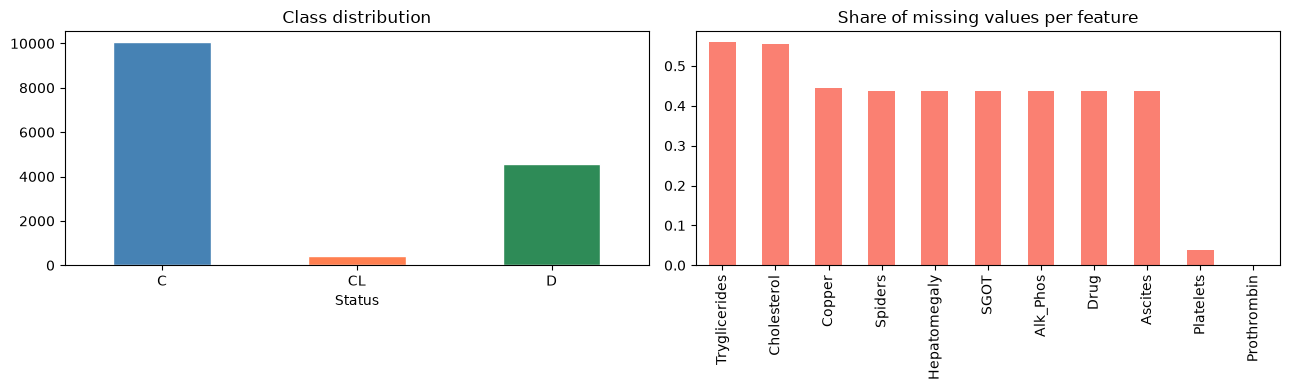

In [3]:
print(train[TARGET].value_counts(normalize=True).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
train[TARGET].value_counts().reindex(CLASSES).plot(
    kind='bar', ax=axes[0], color=['steelblue', 'coral', 'seagreen'], edgecolor='white')
axes[0].set_title('Class distribution')
axes[0].tick_params(axis='x', rotation=0)

missing = train.isnull().mean().sort_values(ascending=False)
missing[missing > 0].plot(kind='bar', ax=axes[1], color='salmon')
axes[1].set_title('Share of missing values per feature')
plt.tight_layout()
plt.show()

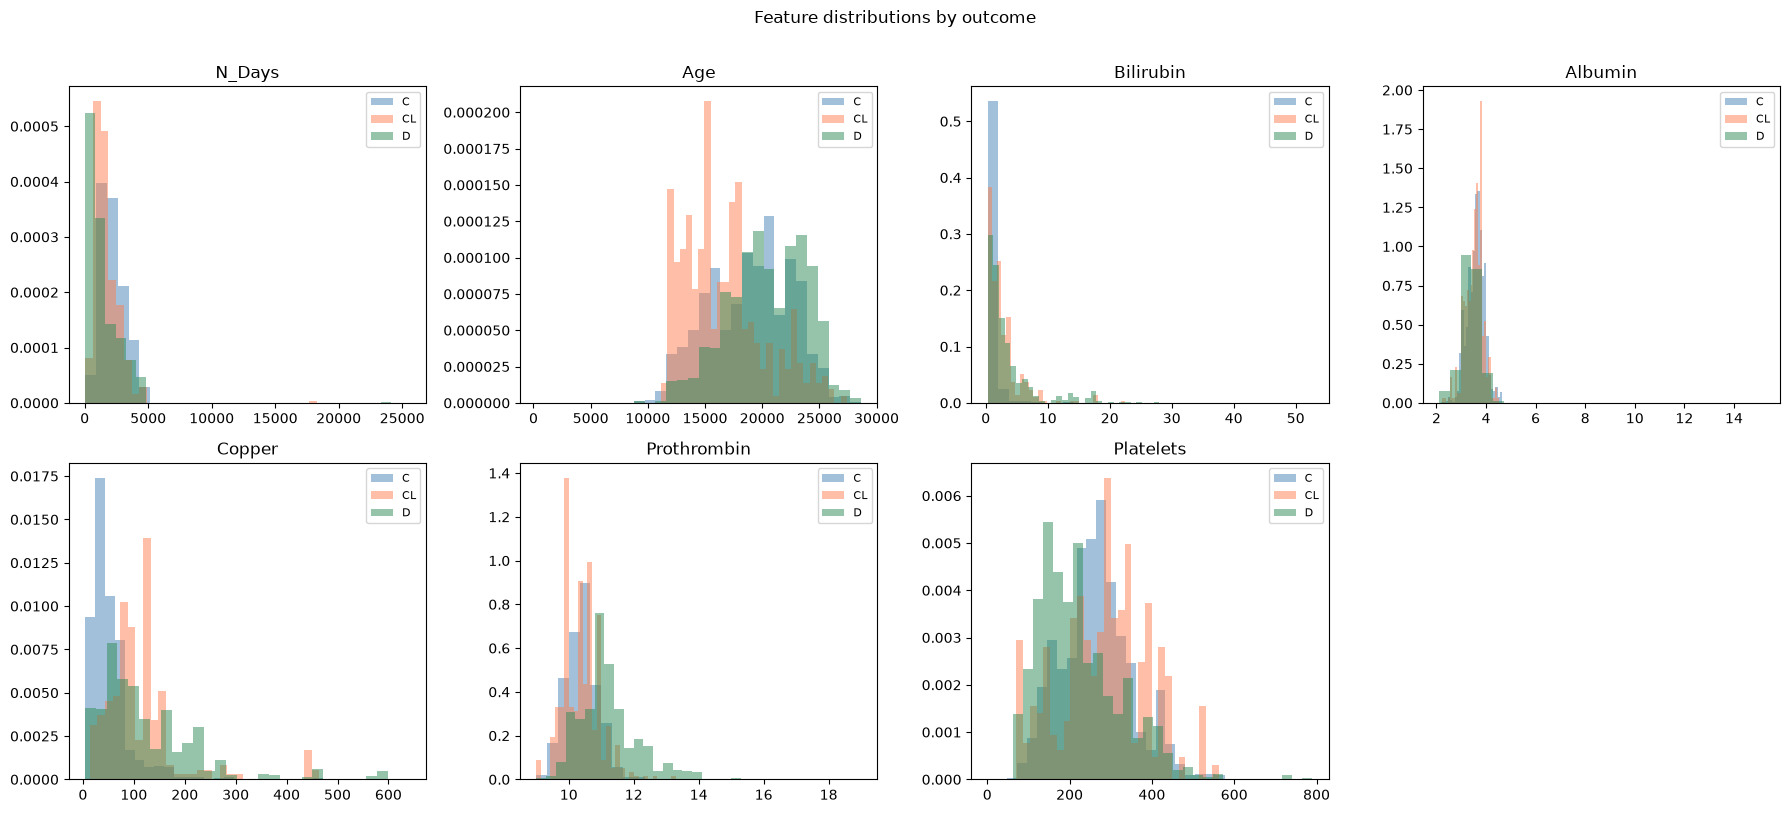

In [4]:
num_features = ['N_Days', 'Age', 'Bilirubin', 'Albumin', 'Copper', 'Prothrombin', 'Platelets']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for ax, feat in zip(axes, num_features):
    for cls, color in zip(CLASSES, ['steelblue', 'coral', 'seagreen']):
        ax.hist(train.loc[train[TARGET] == cls, feat].dropna(), bins=30,
                alpha=0.5, label=cls, color=color, density=True)
    ax.set_title(feat)
    ax.legend(fontsize=8)
axes[-1].axis('off')

plt.suptitle('Feature distributions by outcome', y=1.01)
plt.tight_layout()
plt.show()

## 4. Preprocessing & Feature Engineering

In [5]:
def encode(df):
    df = df.copy()
    binary_map = {'Y': 1, 'N': 0, 'M': 1, 'F': 0}
    for col in ['Sex', 'Ascites', 'Hepatomegaly', 'Spiders']:
        df[col] = df[col].map(binary_map)
    df['Drug']  = df['Drug'].map({'D-penicillamine': 1, 'Placebo': 0})
    df['Edema'] = df['Edema'].map({'N': 0, 'S': 1, 'Y': 2})
    return df

def add_features(df):
    df = df.copy()
    df['Age_years']        = df['Age'] / 365.25
    df['Bili_Protime']     = df['Bilirubin'] * df['Prothrombin']                         # MELD-like proxy
    df['ALBI_proxy']       = np.log1p(df['Bilirubin']) * 0.66 - df['Albumin'] * 0.085     # ALBI-like score
    df['Copper_Albumin']   = df['Copper'] / (df['Albumin'] + 1e-9)
    df['Platelet_Protime'] = df['Platelets'] / (df['Prothrombin'] + 1e-9)
    for col in ['Bilirubin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'N_Days']:
        df[f'log_{col}'] = np.log1p(df[col])
    return df

train = add_features(encode(train))
test  = add_features(encode(test))

feature_cols = [c for c in train.columns if c not in ['id', TARGET]]

# Impute with medians computed on the TRAINING set only (same values applied to test)
medians = train[feature_cols].median()
X       = train[feature_cols].fillna(medians)
X_test  = test[feature_cols].fillna(medians)

class_to_idx = {c: i for i, c in enumerate(CLASSES)}
y = train[TARGET].map(class_to_idx).values

print(f'Features: {len(feature_cols)} | Train rows: {len(X)}')

Features: 29 | Train rows: 15000


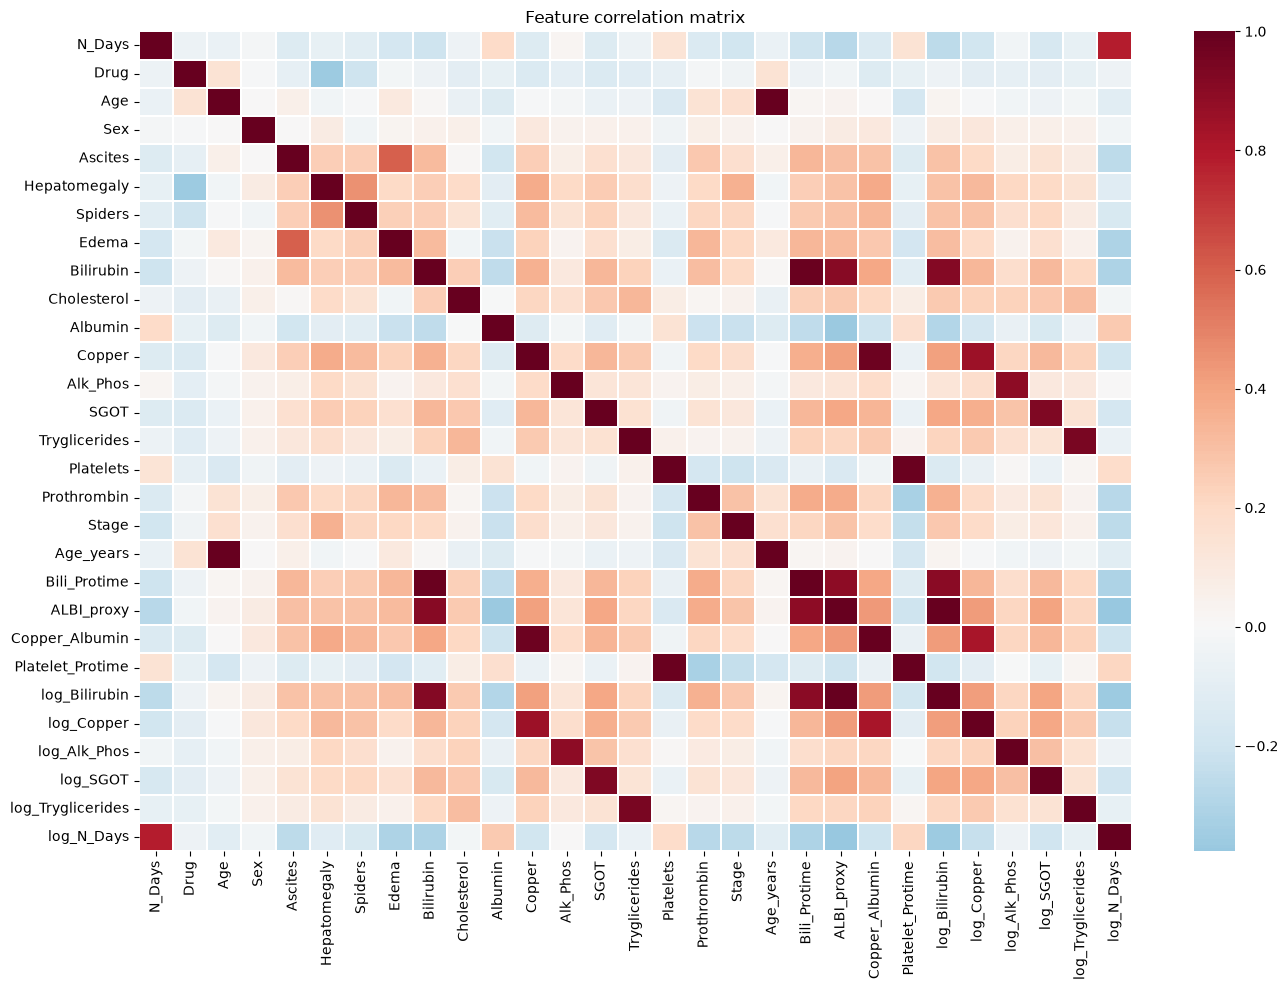

In [6]:
plt.figure(figsize=(14, 10))
sns.heatmap(X.corr(), cmap='RdBu_r', center=0, linewidths=0.3)
plt.title('Feature correlation matrix')
plt.tight_layout()
plt.show()

## 5. LightGBM — Stratified K-Fold Cross-Validation

In [7]:
params = dict(
    objective         = 'multiclass',
    n_estimators      = 3000,
    learning_rate     = 0.02,
    num_leaves        = 63,
    min_child_samples = 20,
    subsample         = 0.8,
    subsample_freq    = 1,
    colsample_bytree  = 0.8,
    reg_alpha         = 0.1,
    reg_lambda        = 1.0,
    class_weight      = 'balanced',   # up-weights the rare CL class
    random_state      = SEED,
    n_jobs            = -1,
    verbose           = -1,
)

N_FOLDS    = 5
skf        = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
oof_probs  = np.zeros((len(X), len(CLASSES)))
test_probs = np.zeros((len(X_test), len(CLASSES)))

for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    model = lgb.LGBMClassifier(**params)
    model.fit(
        X.iloc[tr_idx], y[tr_idx],
        eval_set=[(X.iloc[val_idx], y[val_idx])],
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    oof_probs[val_idx] = model.predict_proba(X.iloc[val_idx])
    test_probs        += model.predict_proba(X_test) / N_FOLDS

    print(f'Fold {fold} | Log loss: {log_loss(y[val_idx], oof_probs[val_idx]):.4f} '
          f'| Best iter: {model.best_iteration_}')

oof_ll = log_loss(y, oof_probs)
print(f'\nOOF log loss: {oof_ll:.4f}')

Fold 1 | Log loss: 0.4025 | Best iter: 529


Fold 2 | Log loss: 0.3868 | Best iter: 502


Fold 3 | Log loss: 0.3842 | Best iter: 506


Fold 4 | Log loss: 0.3797 | Best iter: 496


Fold 5 | Log loss: 0.4116 | Best iter: 496

OOF log loss: 0.3930


## 6. Out-of-Fold Analysis

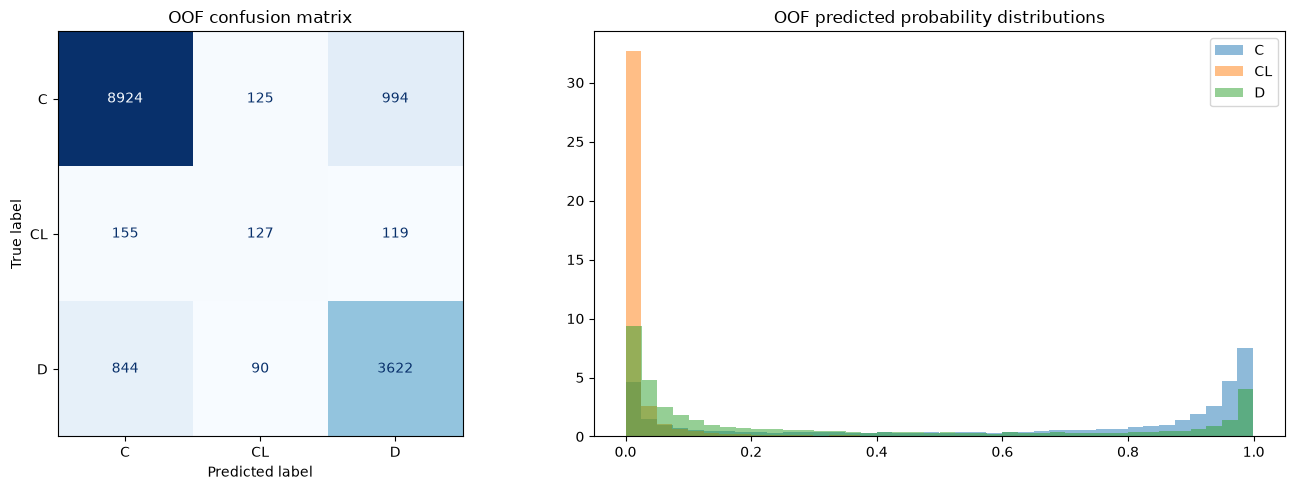

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y, oof_probs.argmax(axis=1))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('OOF confusion matrix')

for i, cls in enumerate(CLASSES):
    axes[1].hist(oof_probs[:, i], bins=40, alpha=0.5, label=cls, density=True)
axes[1].set_title('OOF predicted probability distributions')
axes[1].legend()

plt.tight_layout()
plt.show()

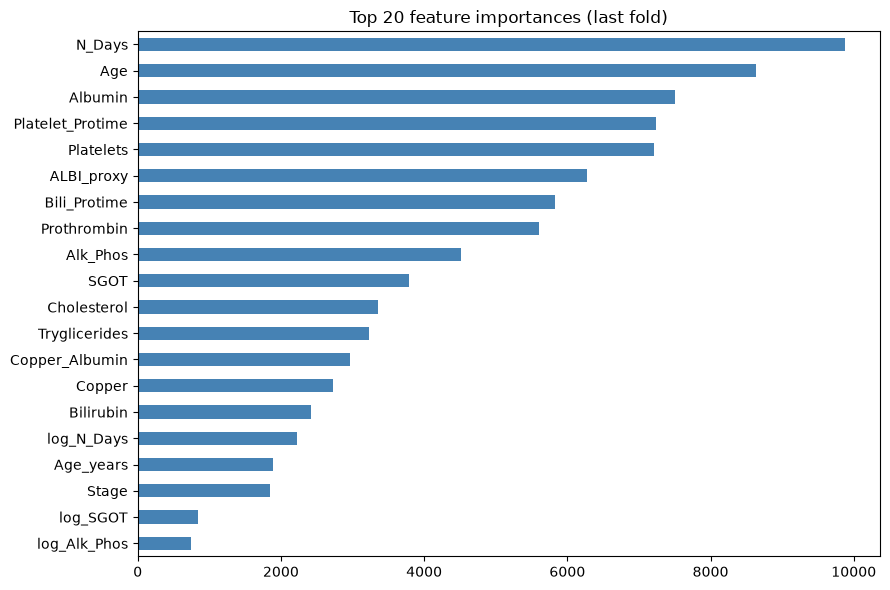

In [9]:
feat_imp = pd.Series(model.feature_importances_, index=feature_cols)
feat_imp.nlargest(20).sort_values().plot(kind='barh', figsize=(9, 6), color='steelblue')
plt.title('Top 20 feature importances (last fold)')
plt.tight_layout()
plt.show()

## 7. Generate Submission

In [10]:
test_probs = test_probs / test_probs.sum(axis=1, keepdims=True)

submission = pd.DataFrame({'id': test['id']})
for i, cls in enumerate(CLASSES):
    submission[f'Status_{cls}'] = test_probs[:, i]

submission.to_csv('submission.csv', index=False)
print(f'Saved {len(submission)} predictions to submission.csv')
submission.head()

Saved 10000 predictions to submission.csv


,id,Status_C,Status_CL,Status_D
0,15000,0.863490,0.001892,0.134618
1,15001,0.376375,0.006584,0.617040
2,15002,0.963778,0.001450,0.034772
3,15003,0.923414,0.024877,0.051709
4,15004,0.004064,0.000441,0.995495


## 8. Ideas to Improve

- **Think about the metric.** Log loss rewards *well-calibrated* probabilities. Does
`class_weight='balanced'` help or hurt calibration? Check it with cross-validation.
- **Missing values.** Tree models handle `NaN` natively — is median imputation needed?
Are the missing values random, or do they follow a pattern?
- Hyperparameter tuning (smaller trees often calibrate better), XGBoost / CatBoost, blending.